In [1]:
%pip install numpy pandas matplotlib seaborn opencv-python scikit-learn scikit-image pillow imagehash joblib

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   --------- ------------------------------ 2.9/11.9 MB 22.4 MB/s eta 0:00:01
   --------------------------- ------------ 8.1/11.9 MB 24.9 MB/s eta 0:00:01
   ---------------------------------------- 11.9/11.9 MB 22.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 12.0 MB/s  0:00:00
   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ------------------- -------------------- 2.1/4.3 MB 9.9 MB/s eta 0:00:01
   ---------------------------------------  4.2/4.3 MB 10.4 MB/s eta 0:00:01
   ---------------------------------------- 4.3/4.3 MB 9.5 MB/s  0:00:00

   ---------------------------------------- 0/7 [tifffile]
   ---------------------------------------- 0/7 [tifffile]
   ---------------------------------------- 0/7 [tifffile]
   ---------------------------------------- 0/7 [tifffile]
   --------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [4]:
root = Path.cwd().resolve()

if root.name == "notebooks":
    root = root.parent

data = root / "datasets"

print("Project folder:", root)
print("Dataset exists:", data.exists())
print("Training exists:", (data / "Training").exists())
print("Testing exists:", (data / "Testing").exists())

Project folder: C:\Users\tejas\Brain_Tumour_Project
Dataset exists: True
Training exists: True
Testing exists: True


In [7]:
rows = []

for split in ["Training", "Testing"]:
    folder = data / split

    for category in sorted(folder.iterdir()):
        if category.is_dir():
            for img in sorted(category.iterdir()):
                if img.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                    rows.append({
                        "filename": str(img.relative_to(data)),
                        "label": category.name,
                        "original_split": split
                    })

df = pd.DataFrame(rows)

print("Total images:", len(df))
counts = df.groupby(["original_split", "label"]).size()

print(counts)
print("\nTotal images:", len(df))
print("\nClass totals:")
print(df["label"].value_counts())

Total images: 7200
original_split  label     
Testing         glioma         400
                meningioma     400
                notumor        400
                pituitary      400
Training        glioma        1400
                meningioma    1400
                notumor       1400
                pituitary     1400
dtype: int64

Total images: 7200

Class totals:
label
glioma        1800
meningioma    1800
notumor       1800
pituitary     1800
Name: count, dtype: int64


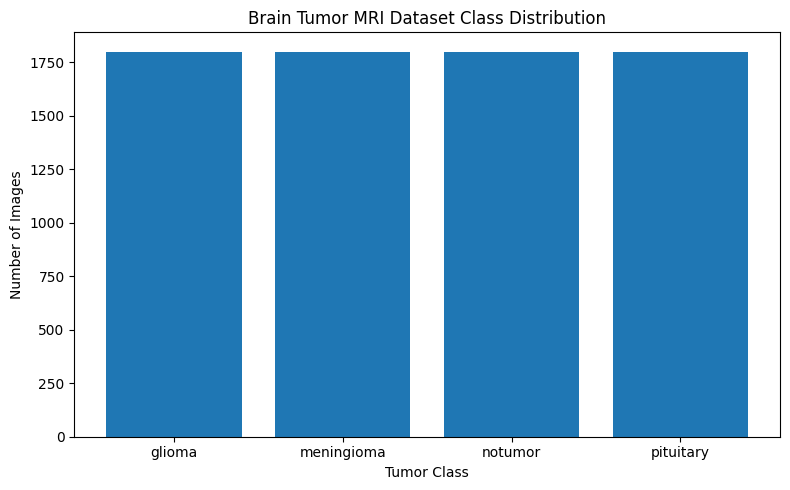

In [8]:
class_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(class_counts.index, class_counts.values)

plt.title("Brain Tumor MRI Dataset Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

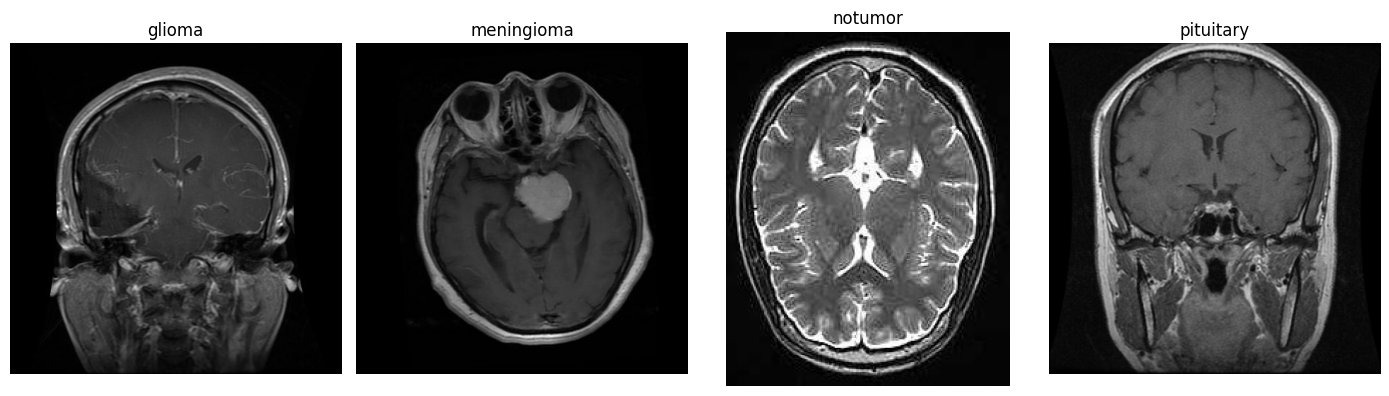

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, label in zip(axes, sorted(df["label"].unique())):
    row = df[df["label"] == label].iloc[0]
    img = cv2.imread(str(data / row["filename"]), 0)

    ax.imshow(img, cmap="gray")
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import imagehash
from PIL import Image

In [12]:
def get_hash(filename):
    with Image.open(data / filename) as img:
        return str(imagehash.phash(img.convert("L")))

df["phash"] = df["filename"].apply(get_hash)

print("Total images:", len(df))
print("Unique hashes:", df["phash"].nunique())
print("Repeated hashes:", df.duplicated("phash").sum())

Total images: 7200
Unique hashes: 6212
Repeated hashes: 988


In [13]:
duplicates = df[df.duplicated("phash", keep=False)]

print("Images in repeated-hash groups:", len(duplicates))

display(
    duplicates[
        ["filename", "label", "original_split", "phash"]
    ].sort_values("phash").head(20)
)

Images in repeated-hash groups: 1580


,filename,label,original_split,phash
5845,Testing\glioma\Te-gl_32.jpg,glioma,Testing,801f157e5bda9a98
5921,Testing\glioma\Te-gl_389.jpg,glioma,Testing,801f157e5bda9a98
1601,Training\meningioma\Tr-me_109.jpg,meningioma,Training,801f5ffa29687d21
6324,Testing\meningioma\Te-me_30.jpg,meningioma,Testing,801f5ffa29687d21
1956,Training\meningioma\Tr-me_239.jpg,meningioma,Training,80375f693ab07c65
6178,Testing\meningioma\Te-me_167.jpg,meningioma,Testing,80375f693ab07c65
2826,Training\notumor\Tr-no_1021.jpg,notumor,Training,804a4ba93fb57c96
3650,Training\notumor\Tr-no_503.jpg,notumor,Training,804a4ba93fb57c96
3033,Training\notumor\Tr-no_1208.jpg,notumor,Training,80544fab6f813ab7
3547,Training\notumor\Tr-no_410.jpg,notumor,Training,80544fab6f813ab7


In [14]:
train_hashes = set(
    df[df["original_split"] == "Training"]["phash"]
)

test_hashes = set(
    df[df["original_split"] == "Testing"]["phash"]
)

common_hashes = train_hashes.intersection(test_hashes)

print("Hashes shared between Training and Testing:", len(common_hashes))

overlap = df[df["phash"].isin(common_hashes)]

print("Images involved in train-test overlap:", len(overlap))

display(
    overlap[
        ["filename", "label", "original_split", "phash"]
    ].sort_values("phash").head(20)
)

Hashes shared between Training and Testing: 294
Images involved in train-test overlap: 855


,filename,label,original_split,phash
1601,Training\meningioma\Tr-me_109.jpg,meningioma,Training,801f5ffa29687d21
6324,Testing\meningioma\Te-me_30.jpg,meningioma,Testing,801f5ffa29687d21
1956,Training\meningioma\Tr-me_239.jpg,meningioma,Training,80375f693ab07c65
6178,Testing\meningioma\Te-me_167.jpg,meningioma,Testing,80375f693ab07c65
3163,Training\notumor\Tr-no_1325.jpg,notumor,Training,80625f4b3a27799d
6706,Testing\notumor\Te-no_375.jpg,notumor,Testing,80625f4b3a27799d
1603,Training\meningioma\Tr-me_1091.jpg,meningioma,Training,811e1fe87aa53ac5
6395,Testing\meningioma\Te-me_95.jpg,meningioma,Testing,811e1fe87aa53ac5
1613,Training\meningioma\Tr-me_110.jpg,meningioma,Training,811e63e81eb50bf9
6186,Testing\meningioma\Te-me_174.jpg,meningioma,Testing,811e63e81eb50bf9


In [15]:
conflicts = df.groupby("phash")["label"].nunique()

conflicting_hashes = conflicts[conflicts > 1].index

print("Hashes associated with multiple classes:", len(conflicting_hashes))

display(
    df[df["phash"].isin(conflicting_hashes)]
    [["filename", "label", "original_split", "phash"]]
    .sort_values("phash")
    .head(20)
)

Hashes associated with multiple classes: 1


,filename,label,original_split,phash
2199,Training\meningioma\Tr-me_458.jpg,meningioma,Training,901a7f616de436a6
5965,Testing\glioma\Te-gl_68.jpg,glioma,Testing,901a7f616de436a6
6396,Testing\meningioma\Te-me_96.jpg,meningioma,Testing,901a7f616de436a6


In [16]:
import hashlib

def get_sha256(filename):
    h = hashlib.sha256()
    with open(data / filename, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

df["sha256"] = df["filename"].apply(get_sha256)

print("Total images:", len(df))
print("Unique exact hashes:", df["sha256"].nunique())
print("Exact duplicate copies:", df.duplicated("sha256").sum())

Total images: 7200
Unique exact hashes: 7013
Exact duplicate copies: 187


In [17]:
train_exact = set(
    df[df["original_split"] == "Training"]["sha256"]
)

test_exact = set(
    df[df["original_split"] == "Testing"]["sha256"]
)

common_exact = train_exact.intersection(test_exact)

print("Exact hashes shared across train/test:", len(common_exact))

exact_overlap = df[df["sha256"].isin(common_exact)]

print("Images in exact overlapping groups:", len(exact_overlap))

print("\nOverlap by split:")
print(exact_overlap["original_split"].value_counts())

Exact hashes shared across train/test: 0
Images in exact overlapping groups: 0

Overlap by split:
Series([], Name: count, dtype: int64)


In [18]:
conflicts = df.groupby("sha256")["label"].nunique()

print(
    "Exact duplicate groups with conflicting labels:",
    (conflicts > 1).sum()
)

Exact duplicate groups with conflicting labels: 0


Potential overlapping pairs: 294


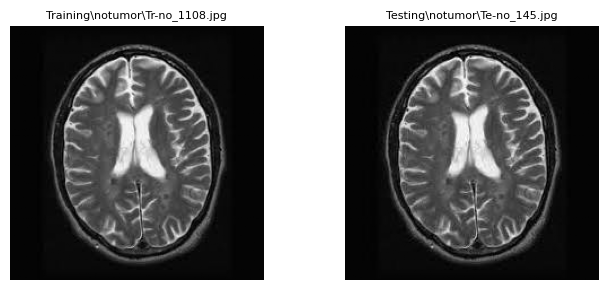

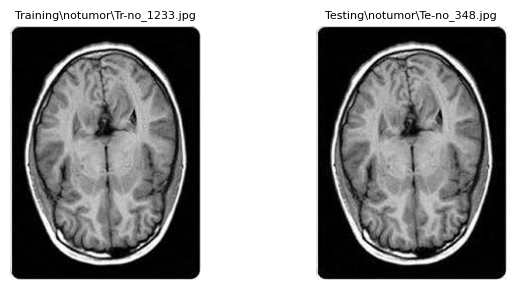

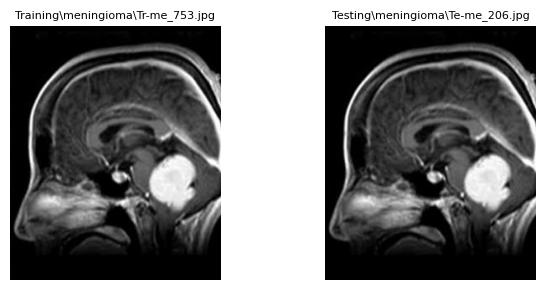

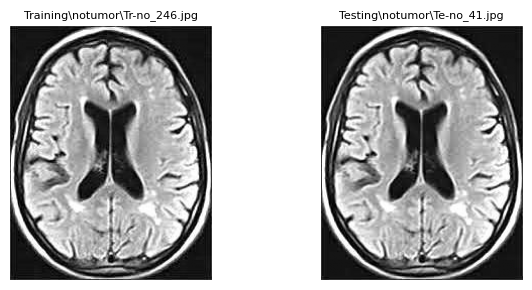

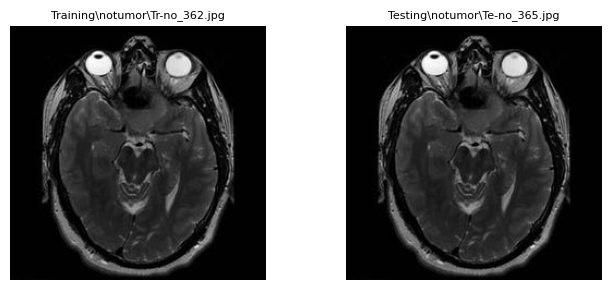

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

pairs = []

for h in common_hashes:
    group = df[df["phash"] == h]

    train = group[group["original_split"] == "Training"]
    test = group[group["original_split"] == "Testing"]

    if len(train) and len(test):
        pairs.append((
            train.iloc[0]["filename"],
            test.iloc[0]["filename"]
        ))

print("Potential overlapping pairs:", len(pairs))

for train_file, test_file in pairs[:5]:
    fig, axes = plt.subplots(1, 2, figsize=(7, 3))

    for ax, name in zip(axes, [train_file, test_file]):
        with Image.open(data / name) as img:
            ax.imshow(img.convert("L"), cmap="gray")
        ax.set_title(name, fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [20]:
from pathlib import Path
import pandas as pd

train = df[df["original_split"] == "Training"].copy()
test = df[df["original_split"] == "Testing"].copy()

test_hashes = set(test["phash"])

overlap = train["phash"].isin(test_hashes)

print("Training images excluded:", overlap.sum())

train_clean = train[~overlap].copy()

print("Remaining training images:", len(train_clean))
print("Original testing images:", len(test))

Training images excluded: 485
Remaining training images: 5115
Original testing images: 1600


In [22]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

train_clean = train_clean.copy()
test = test.copy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_clean,
        groups=train_clean["phash"].astype(str)
    )
)

train_part = train_clean.iloc[train_idx].copy()
val_part = train_clean.iloc[val_idx].copy()

train_part["split"] = "train"
val_part["split"] = "val"
test["split"] = "test"

split_df = pd.concat(
    [train_part, val_part, test],
    ignore_index=True
)

print(split_df.groupby(["split", "label"]).size())
print("\nTotal images:", len(split_df))

split  label     
test   glioma         400
       meningioma     400
       notumor        400
       pituitary      400
train  glioma        1177
       meningioma    1112
       notumor        869
       pituitary     1203
val    glioma         219
       meningioma     181
       notumor        159
       pituitary      195
dtype: int64

Total images: 6715


In [23]:
overlap = split_df.groupby("phash")["split"].nunique()

print(
    "Perceptual hash groups across splits:",
    (overlap > 1).sum()
)

print("\nSplit sizes:")
print(split_df["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(split_df["split"], split_df["label"]))

Perceptual hash groups across splits: 0

Split sizes:
split
train    4361
test     1600
val       754
Name: count, dtype: int64

Class distribution:
label  glioma  meningioma  notumor  pituitary
split                                        
test      400         400      400        400
train    1177        1112      869       1203
val       219         181      159        195


In [24]:
print("Duplicate filenames:", split_df["filename"].duplicated().sum())

print("Missing values:")
print(split_df[["filename", "label", "split"]].isnull().sum())

print("Hash overlap:",
      (split_df.groupby("phash")["split"].nunique() > 1).sum())

print("Label conflicts:",
      (split_df.groupby("phash")["label"].nunique() > 1).sum())

Duplicate filenames: 0
Missing values:
filename    0
label       0
split       0
dtype: int64
Hash overlap: 0
Label conflicts: 1


In [25]:
(root / "shared").mkdir(parents=True, exist_ok=True)

split_df[["filename", "label", "split"]].to_csv(
    root / "shared" / "split.csv",
    index=False
)

print("Split saved successfully!")

Split saved successfully!


In [26]:
print("Duplicate filenames:",
      split_df["filename"].duplicated().sum())

print("Missing values:")
print(split_df[["filename", "label", "split"]].isnull().sum())

print("Hash overlap:",
      (split_df.groupby("phash")["split"].nunique() > 1).sum())

print("Label conflicts:",
      (split_df.groupby("phash")["label"].nunique() > 1).sum())

Duplicate filenames: 0
Missing values:
filename    0
label       0
split       0
dtype: int64
Hash overlap: 0
Label conflicts: 1


In [27]:
conflict_hashes = split_df.groupby("phash")["label"].nunique()
conflict_hashes = conflict_hashes[conflict_hashes > 1].index

conflict_images = split_df[
    split_df["phash"].isin(conflict_hashes)
]

display(
    conflict_images[
        ["filename", "label", "split", "phash"]
    ]
)

,filename,label,split,phash
5480,Testing\glioma\Te-gl_68.jpg,glioma,test,901a7f616de436a6
5911,Testing\meningioma\Te-me_96.jpg,meningioma,test,901a7f616de436a6


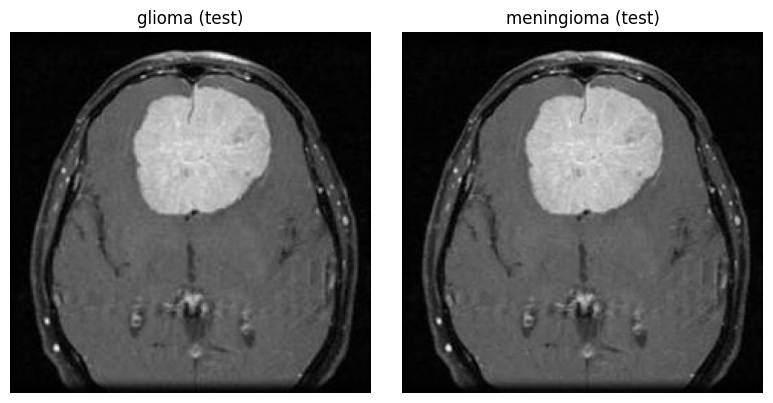

In [28]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(
    1, len(conflict_images),
    figsize=(4 * len(conflict_images), 4),
    squeeze=False
)

for ax, (_, row) in zip(axes[0], conflict_images.iterrows()):
    with Image.open(data / row["filename"]) as img:
        ax.imshow(img.convert("L"), cmap="gray")

    ax.set_title(f'{row["label"]} ({row["split"]})')
    ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
print("Before:", len(split_df))

split_df = split_df[
    ~split_df["phash"].isin(conflict_hashes)
].copy()

print("After:", len(split_df))

print("\nRemaining label conflicts:",
      (split_df.groupby("phash")["label"].nunique() > 1).sum())

Before: 6715
After: 6713

Remaining label conflicts: 0


In [30]:
split_df[["filename", "label", "split"]].to_csv(
    root / "shared" / "split.csv",
    index=False
)

print("Updated split.csv successfully!")

Updated split.csv successfully!


In [31]:
print(pd.crosstab(split_df["split"], split_df["label"]))

print("\nTotal images:", len(split_df))

print("Label conflicts:",
      (split_df.groupby("phash")["label"].nunique() > 1).sum())

print("Hash overlap:",
      (split_df.groupby("phash")["split"].nunique() > 1).sum())

label  glioma  meningioma  notumor  pituitary
split                                        
test      399         399      400        400
train    1177        1112      869       1203
val       219         181      159        195

Total images: 6713
Label conflicts: 0
Hash overlap: 0
